# 01 · Retraining is an intervention: regression to the mean, placebo, A/B and RDD

**Block 8 · W44.** A retraining policy fires when a series' recent error is high, and a dashboard then shows the
error before and after. This notebook shows why that dashboard is biased by construction, how big the bias is,
and the two designs that measure the real effect: a randomised holdout, and a regression discontinuity at the
trigger threshold.

| § | Question | Short answer |
|---|---|---|
| 1 | Why does the error fall after a refit that does nothing? | We selected series on a high error, part of which was noise: regression to the mean. |
| 2 | How wrong is the dashboard? | It shows 3 times the true effect (a bias of 196%); a placebo alone shows 197%. |
| 3 | Does a more careful threshold help? | No: the stricter the threshold, the larger the fake effect. |
| 4 | What measures the true effect? | A/B among triggered series (or DiD with a random control), validated by a placebo. |
| 5 | How big must the holdout be? | 5% gives a usable interval for 0.0012 of extra error per park series. |
| 6 | Can we do without a holdout? | Yes, at the threshold: a sharp regression discontinuity (RDD). |
| 7 | What does the RDD estimate, exactly? | The effect for series just above the threshold, not the average effect. |

> **How to read this notebook.** The boxed notes follow a fixed code:
> **Intuition**, the idea without equations · **Example**, a computed experiment ·
> **Watch out**, the trap to avoid · **Takeaway**, the memo to keep.

In [1]:

import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

from w44_retraining import causal as C
from w44_retraining import viz

viz.setup()
export = viz.exporter("../figures")


def table(rows, cols, fmt="{:+.4f}"):
    """Render a list of row tuples as a Markdown table (floats formatted with fmt)."""
    cell = lambda v: fmt.format(v) if isinstance(v, float) else str(v)
    lines = ["| " + " | ".join(cols) + " |", "|" + "---|" * len(cols)]
    lines += ["| " + " | ".join(cell(v) for v in r) + " |" for r in rows]
    display(Markdown("\n".join(lines)))


out = C.study()
TRUE = out["truth"]

## 1. The mechanism: why the error falls after a refit that does nothing

**The simulated park.** Each series $i$ carries a **staleness bias** $b_i = |\mathcal N(0, 0.5^2)|$: how far its
deployed model has drifted. Its observed error at each step is $|b_i + \varepsilon|$ with noise
$\varepsilon \sim \mathcal N(0, 1)$, and the dashboard averages it over a 14-step window. A refit removes 30% of
the bias. We call

- **pre** the mean error over the 14 steps before the decision, **post** over the 14 steps after;
- **triggered** the series whose pre-error exceeds the threshold, 1.05;
- **placebo** a "refit" that changes nothing: the true effect is exactly zero.

> **Intuition.** A series is triggered when its *measured* error is high. That happens for two reasons: its bias
> is really high, or its noise happened to be high over those 14 steps. The noise does not persist. Over the next
> 14 steps it is average again, so the error falls even if nothing was done.

### Example: the placebo, series by series

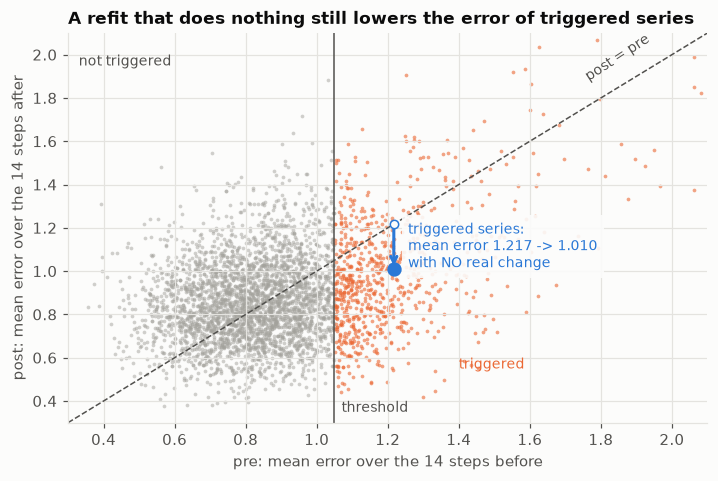

20.4% of the park triggered; triggered series: pre 1.2170, post 1.0099, difference -0.2072


In [2]:
d = C.simulate(placebo=True)
rng = np.random.default_rng(0)
show = rng.choice(d["pre"].size, 4000, replace=False)
fired = d["fired"]
fig, ax = plt.subplots(figsize=(7.5, 4.6))
ax.scatter(d["pre"][show][~fired[show]], d["post"][show][~fired[show]], s=6, color=viz.MUTED, alpha=0.5, lw=0)
ax.scatter(d["pre"][show][fired[show]], d["post"][show][fired[show]], s=6, color=viz.ORANGE, alpha=0.6, lw=0)
lim = (0.3, 2.1)
ax.plot(lim, lim, color=viz.TEXT_2, lw=1, ls="--")
ax.axvline(1.05, color=viz.TEXT_2, lw=1)
mp, mq = d["pre"][fired].mean(), d["post"][fired].mean()
ax.scatter([mp], [mq], color=viz.BLUE, s=70, zorder=3)
ax.annotate("", (mp, mq), (mp, mp), arrowprops=dict(arrowstyle="->", color=viz.BLUE, lw=2))
ax.scatter([mp], [mp], color=viz.BLUE, s=30, zorder=3, facecolor=viz.SURFACE)
ax.text(mp + 0.04, (mp + mq) / 2, f"triggered series:\nmean error {mp:.3f} -> {mq:.3f}\nwith NO real change",
        color=viz.BLUE, va="center", fontsize=9, bbox=dict(facecolor=viz.SURFACE, edgecolor="none", alpha=0.9))
ax.text(1.07, 0.35, "threshold", color=viz.TEXT_2, fontsize=9)
ax.text(1.75, 1.88, "post = pre", color=viz.TEXT_2, fontsize=9, rotation=33)
ax.text(0.33, 1.95, "not triggered", color=viz.TEXT_2, fontsize=9)
ax.text(1.40, 0.55, "triggered", color=viz.ORANGE, fontsize=9)
ax.set_xlim(lim); ax.set_ylim(lim)
ax.set_xlabel("pre: mean error over the 14 steps before"); ax.set_ylabel("post: mean error over the 14 steps after")
ax.set_title("A refit that does nothing still lowers the error of triggered series")
export(fig, "rtm_scatter"); plt.show()
print(f"{fired.mean():.1%} of the park triggered; triggered series: pre {mp:.4f}, post {mq:.4f}, "
      f"difference {mq - mp:+.4f}")

The orange cloud sits below the diagonal: for triggered series, post is lower than pre on average, although the
placebo changed nothing. The untriggered series sit slightly *above* the diagonal, for the mirror reason: their
noise was unusually low.

## 2. How wrong is the dashboard?

The **true effect** of a real refit (30% of the bias removed) on the triggered series is measured once and for
all by randomisation on 400,000 series: half of the triggered series are refit, half are not, and we compare
their post-errors. Then we compute what the dashboard shows: post minus pre on the refit series.

In [3]:
table([("true effect (randomised, 400,000 series)", TRUE, ""),
       ("dashboard: naive post - pre, real refit", out["dashboard"]["naive"],
        f"{abs(out['dashboard']['naive']) / abs(TRUE):.1f} x the true effect; bias "
        f"{abs(out['dashboard']['naive'] - TRUE) / abs(TRUE):.0%} of it"),
       ("dashboard: naive post - pre, placebo", out["placebo_naive"],
        f"{abs(out['placebo_naive']) / abs(TRUE):.0%} of the true effect")],
      ["quantity", "value", "reading"])
print(f"share of the displayed gain that is regression to the mean: {out['placebo_naive'] / out['dashboard']['naive']:.0%}")

| quantity | value | reading |
|---|---|---|
| true effect (randomised, 400,000 series) | -0.1053 |  |
| dashboard: naive post - pre, real refit | -0.3119 | 3.0 x the true effect; bias 196% of it |
| dashboard: naive post - pre, placebo | -0.2072 | 197% of the true effect |

share of the displayed gain that is regression to the mean: 66%


> **Takeaway.** Two thirds of the gain the dashboard displays is regression to the mean. The instrument is
> perfect; **the selection rule makes the effect**. And refitting every triggered series leaves no control group,
> so the dashboard cannot even be corrected afterwards.

## 3. A stricter threshold makes the fake effect larger

One might think a "careful" policy, which refits only the clearly bad series, is safer. It is the opposite:
the stricter the threshold, the more extreme the selected noise, and the larger the regression to the mean.

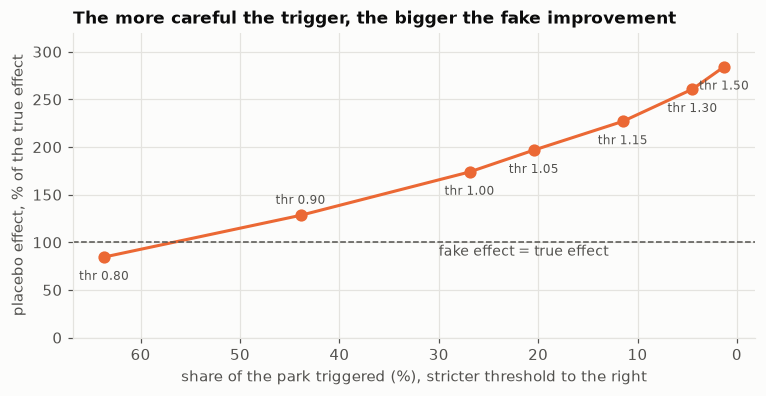

| threshold | triggered | placebo naive effect | % of true effect |
|---|---|---|---|
| 0.80 | 63.7% | -0.0890 | 85% |
| 0.90 | 43.9% | -0.1351 | 128% |
| 1.00 | 26.9% | -0.1830 | 174% |
| 1.05 | 20.4% | -0.2072 | 197% |
| 1.15 | 11.5% | -0.2389 | 227% |
| 1.30 | 4.5% | -0.2745 | 261% |
| 1.50 | 1.3% | -0.2993 | 284% |

In [4]:
th = out["threshold"]
x = [100 * r["fired"] for r in th]
yv = [100 * abs(r["naive"]) / abs(TRUE) for r in th]
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.plot(x, yv, color=viz.ORANGE, marker="o", ms=7)
for r, xi, yi in zip(th, x, yv, strict=True):
    dy = 12 if 85 < yi - 24 < 115 else -24     # keep labels off the reference line
    ax.text(xi, yi + dy, f"thr {r['thr']:.2f}", color=viz.TEXT_2, fontsize=8, ha="center")
ax.axhline(100, color=viz.TEXT_2, lw=1, ls="--")
ax.text(30, 86, "fake effect = true effect", color=viz.TEXT_2, fontsize=9)
ax.invert_xaxis()
ax.set_xlabel("share of the park triggered (%), stricter threshold to the right")
ax.set_ylabel("placebo effect, % of the true effect")
ax.set_ylim(0, 320)
ax.set_title("The more careful the trigger, the bigger the fake improvement")
export(fig, "placebo_vs_threshold"); plt.show()
table([(f"{r['thr']:.2f}", f"{r['fired']:.1%}", r["naive"], f"{abs(r['naive']) / abs(TRUE):.0%}") for r in th],
      ["threshold", "triggered", "placebo naive effect", "% of true effect"])

> **Watch out.** At a threshold that triggers 1.3% of the park, a refit that does nothing shows 284% of the
> effect of a real one. This is exactly how a drift-monitoring vendor can report a large "return on investment"
> without lying about a single number: the figure is real, its attribution is not.

## 4. Measuring the true effect: A/B among triggered series

Among the triggered series, refit a **random half** and keep the other half as a control. Both groups were
selected by the same rule, so both regress to the mean by the same amount; the difference of their post-errors
isolates the refit. A **difference-in-differences** (DiD), (post - pre) of the refit group minus (post - pre) of
the control group, works here too, because the control is random.

The **placebo test** checks the design: rerun it with a placebo refit, and a valid estimator must return zero.

| estimator | real refit (true -0.1053) | placebo (true 0) |
|---|---|---|
| naive post - pre | -0.3033 | -0.1974 |
| DiD | -0.0992 | +0.0067 |
| A/B | -0.0993 | +0.0066 |
| A/B 95% CI | [-0.1141, -0.0844] | [-0.0102, +0.0234] |

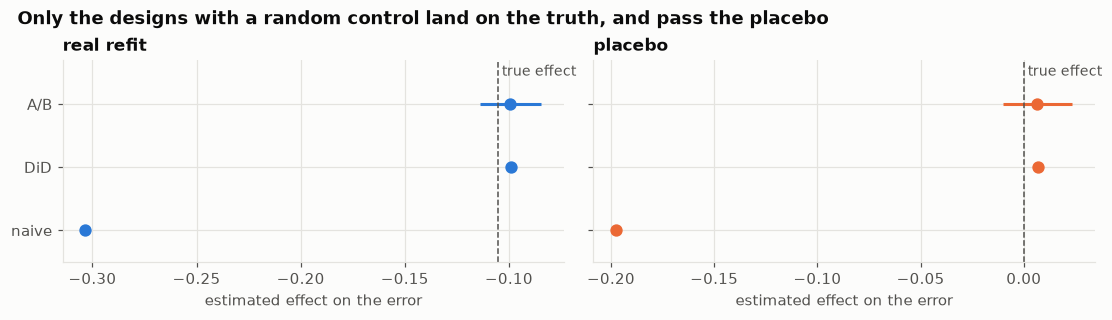

In [5]:
ab, ap = out["ab"], out["ab_placebo"]
table([("naive post - pre", ab["naive"], ap["naive"]),
       ("DiD", ab["did"], ap["did"]),
       ("A/B", ab["ab"], ap["ab"]),
       ("A/B 95% CI", f"[{ab['ci'][0]:+.4f}, {ab['ci'][1]:+.4f}]", f"[{ap['ci'][0]:+.4f}, {ap['ci'][1]:+.4f}]")],
      ["estimator", f"real refit (true {TRUE:+.4f})", "placebo (true 0)"])

fig, axs = plt.subplots(1, 2, figsize=(10, 2.8), layout="constrained", sharey=True)
names = ["naive", "DiD", "A/B"]
for ax, res, truth, color, title in ((axs[0], ab, TRUE, viz.BLUE, "real refit"),
                                     (axs[1], ap, 0.0, viz.ORANGE, "placebo")):
    vals = [res["naive"], res["did"], res["ab"]]
    ax.scatter(vals, range(3), color=color, s=50, zorder=3)
    ax.hlines(2, *res["ci"], color=color, lw=2)
    ax.axvline(truth, color=viz.TEXT_2, ls="--", lw=1)
    ax.text(truth, 2.45, " true effect", color=viz.TEXT_2, fontsize=9)
    ax.set_yticks(range(3), names); ax.set_ylim(-0.5, 2.7)
    ax.set_title(title); ax.set_xlabel("estimated effect on the error")
fig.suptitle("Only the designs with a random control land on the truth, and pass the placebo",
             x=0.01, ha="left", fontweight="bold")
export(fig, "estimators"); plt.show()

> **Example.** With 2,080 refit and 2,007 control series, the A/B estimate is -0.0993, 95% CI
> [-0.1141, -0.0844], which contains the true -0.1053. On the placebo, it returns +0.0066 with a CI containing
> zero, while the naive estimator still shows -0.1974.

## 5. How big must the holdout be?

A control series is a series we deliberately leave stale, so the holdout has a service cost: the extra error the
controls carry. A smaller holdout costs less but gives a wider interval.

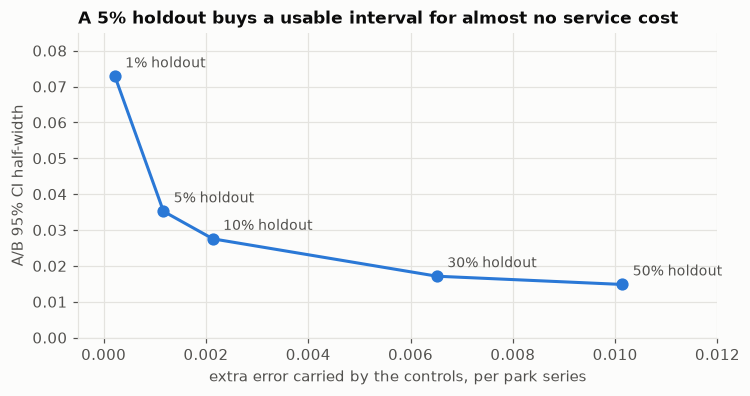

| holdout | controls | A/B | CI half-width | loss per triggered series | loss per park series |
|---|---|---|---|---|---|
| 50% | 2007 | -0.0993 | 0.0148 | 0.0496 | 0.0101 |
| 30% | 1188 | -0.1063 | 0.0171 | 0.0319 | 0.0065 |
| 10% | 389 | -0.1045 | 0.0275 | 0.0104 | 0.0021 |
| 5% | 187 | -0.1144 | 0.0352 | 0.0057 | 0.0012 |
| 1% | 46 | -0.1079 | 0.0728 | 0.0011 | 0.0002 |

In [6]:
ho = out["holdout"]
fig, ax = plt.subplots(figsize=(7.5, 3.6))
ax.plot([r["loss_per_park"] for r in ho], [r["half_width"] for r in ho], color=viz.BLUE, marker="o", ms=7)
for r in ho:
    ax.text(r["loss_per_park"] + 0.0002, r["half_width"] + 0.0025, f"{100 * (1 - r['p']):.0f}% holdout",
            color=viz.TEXT_2, fontsize=9)
ax.set_xlabel("extra error carried by the controls, per park series")
ax.set_ylabel("A/B 95% CI half-width")
ax.set_xlim(-0.0005, 0.012); ax.set_ylim(0, 0.085)
ax.set_title("A 5% holdout buys a usable interval for almost no service cost")
export(fig, "holdout_tradeoff"); plt.show()
table([(f"{100 * (1 - r['p']):.0f}%", r["n_c"], r["ab"], f"{r['half_width']:.4f}", f"{r['loss_per_triggered']:.4f}",
        f"{r['loss_per_park']:.4f}") for r in ho],
      ["holdout", "controls", "A/B", "CI half-width", "loss per triggered series", "loss per park series"])

> **Watch out.** The cost must be stated per **park** series: only 20.4% of the park is triggered, so a 5%
> holdout costs 0.0057 per triggered series but 0.0012 per park series.

## 6. Without a holdout: a regression discontinuity at the threshold

Go back to the dashboard design: **every** series above 1.05 is refit, none below. There is no control group, but
there is a **rule**. Series with a pre-error of 1.04 and 1.06 are almost identical (same expected bias, same
regression to the mean); only the refit differs. So the **jump** of the post-error at the threshold is the effect
of the refit, for series at the threshold. This is a *sharp regression discontinuity*.

**How it is estimated.** On each side, fit a straight line of post on pre, using only series within a
bandwidth $h$ of the threshold and weighting them by $1 - |x|/h$ (closer series count more). The estimate is the
difference of the two intercepts at the threshold, with a heteroscedasticity-robust standard error.

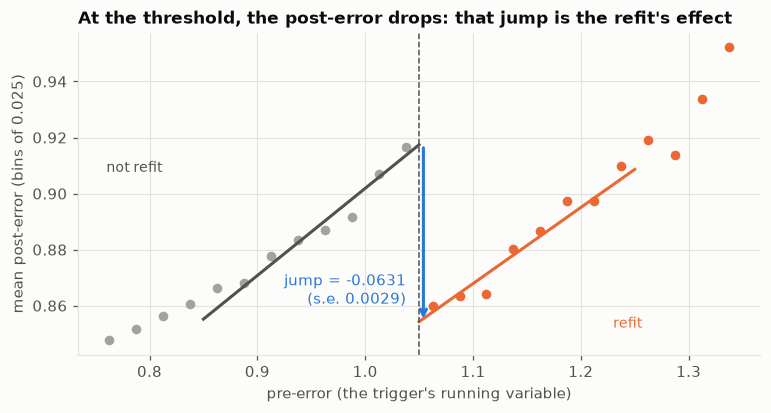

| bandwidth | seed | RDD estimate | s.e. | placebo | placebo s.e. |
|---|---|---|---|---|---|
| 0.05 | 844 | -0.0589 | 0.0059 | +0.0006 | 0.0064 |
| 0.05 | 845 | -0.0621 | 0.0057 | -0.0029 | 0.0062 |
| 0.10 | 844 | -0.0638 | 0.0042 | -0.0044 | 0.0045 |
| 0.10 | 845 | -0.0615 | 0.0040 | -0.0031 | 0.0044 |
| 0.20 | 844 | -0.0631 | 0.0029 | -0.0053 | 0.0032 |
| 0.20 | 845 | -0.0600 | 0.0029 | -0.0028 | 0.0032 |

true effect for triggered series with pre in [1.05, 1.10): -0.0625


In [7]:
thr, bw = 1.05, 0.20
dd = C.simulate(n=200_000, seed=844)
(right, var_r), (left, var_l) = C.rdd_lines(dd, thr, bw)
est, se = C.est_rdd(dd, thr, bw)
edges = np.arange(thr - 0.30, thr + 0.30 + 1e-9, 0.025)
mid = (edges[:-1] + edges[1:]) / 2
binned = np.array([dd["post"][(dd["pre"] >= lo) & (dd["pre"] < hi)].mean()
                   for lo, hi in zip(edges[:-1], edges[1:], strict=True)])
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.scatter(mid[mid < thr], binned[mid < thr], color=viz.MUTED, s=28, zorder=2)
ax.scatter(mid[mid >= thr], binned[mid >= thr], color=viz.ORANGE, s=28, zorder=2)
xl, xr = np.linspace(thr - bw, thr, 20), np.linspace(thr, thr + bw, 20)
ax.plot(xl, left[0] + left[1] * (xl - thr), color=viz.TEXT_2)
ax.plot(xr, right[0] + right[1] * (xr - thr), color=viz.ORANGE)
ax.axvline(thr, color=viz.TEXT_2, lw=1, ls="--")
ax.annotate("", (thr + 0.004, right[0]), (thr + 0.004, left[0]),
            arrowprops=dict(arrowstyle="->", color=viz.BLUE, lw=2))
ax.text(thr - 0.012, left[0] - 0.052, f"jump = {est:+.4f}\n(s.e. {se:.4f})", color=viz.BLUE, va="center", ha="right")
ax.text(thr - 0.29, binned[0] + 0.06, "not refit", color=viz.TEXT_2, fontsize=9)
ax.text(thr + 0.18, binned[-1] - 0.10, "refit", color=viz.ORANGE, fontsize=9)
ax.set_xlabel("pre-error (the trigger's running variable)"); ax.set_ylabel("mean post-error (bins of 0.025)")
ax.set_title("At the threshold, the post-error drops: that jump is the refit's effect")
export(fig, "rdd"); plt.show()

rows = [(f"{r['bw']:.2f}", r["seed"], r["est"], f"{r['se']:.4f}", r["placebo"], f"{r['placebo_se']:.4f}")
        for r in out["rdd"]]
table(rows, ["bandwidth", "seed", "RDD estimate", "s.e.", "placebo", "placebo s.e."])
print(f"true effect for triggered series with pre in [1.05, 1.10): {out['truth_at_threshold']:+.4f}")

> **Intuition.** Regression to the mean is a smooth function of the pre-error: it does not know where the
> threshold is. The refit is the only thing that changes abruptly at 1.05, so a jump there can only be the refit.

The RDD recovers -0.059 to -0.064 against a true -0.0625 at the threshold. Its placebo stays within two standard
errors of zero (the largest is 1.7 s.e.), although all six placebo estimates are slightly negative: a hint of a
small curvature bias of the local linear fit, which grows with the bandwidth. It needs **no holdout**, only that
the pre-error that triggered (or did not trigger) each series is logged.

## 7. What the RDD identifies: the effect at the threshold, not the average

The A/B of section 4 estimates -0.1053, the RDD -0.06. Both are right: they answer different questions. In
this simulation the refit removes a share of the bias, so series far above the threshold, which carry more bias,
gain more. The RDD only sees series at the threshold.

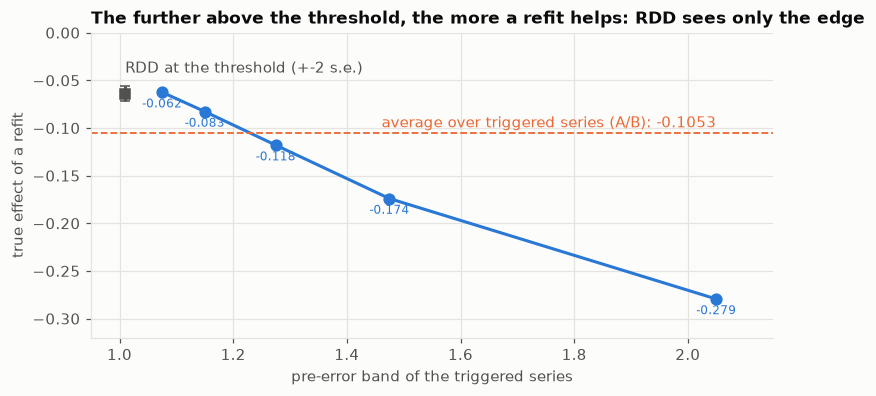

| pre-error band | true effect |
|---|---|
| [1.05, 1.10) | -0.0625 |
| [1.10, 1.20) | -0.0827 |
| [1.20, 1.35) | -0.1180 |
| [1.35, 1.60) | -0.1740 |
| [1.60, 2.50) | -0.2794 |

In [8]:
edges = [1.05, 1.10, 1.20, 1.35, 1.60, 2.50]
eff = C.effect_by_band(0.30, edges)
centres = [(a + b) / 2 for a, b in zip(edges[:-1], edges[1:], strict=True)]
r10 = next(r for r in out["rdd"] if r["bw"] == 0.10 and r["seed"] == 844)
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.plot(centres, eff, color=viz.BLUE, marker="o", ms=7)
ax.axhline(TRUE, color=viz.ORANGE, ls="--", lw=1.2)
ax.text(2.05, TRUE + 0.006, f"average over triggered series (A/B): {TRUE:+.4f}", color=viz.ORANGE, ha="right")
ax.errorbar([thr - 0.04], [r10["est"]], yerr=[2 * r10["se"]], fmt="s", color=viz.TEXT_2, ms=7, capsize=3)
ax.text(thr - 0.04, r10["est"] + 0.022, "RDD at the threshold (+-2 s.e.)", color=viz.TEXT_2)
for c, e in zip(centres, eff, strict=True):
    ax.text(c, e - 0.016, f"{e:+.3f}", color=viz.BLUE, ha="center", fontsize=8)
ax.set_xlim(0.95, 2.15)
ax.set_xlabel("pre-error band of the triggered series"); ax.set_ylabel("true effect of a refit")
ax.set_ylim(-0.32, 0.0)
ax.set_title("The further above the threshold, the more a refit helps: RDD sees only the edge")
export(fig, "rdd_local_vs_average"); plt.show()
table([(f"[{a:.2f}, {b:.2f})", e) for a, b, e in zip(edges[:-1], edges[1:], eff, strict=True)],
      ["pre-error band", "true effect"])

> **Takeaway.** Two designs, two questions:
> - "should we move the threshold a little?" is the RDD's question: the effect at the margin, free from the logs;
> - "what does our retraining policy buy on average?" needs the randomised holdout.
>
> A service contract should require at least one of them, and say which question it answers.

## Summary

1. Triggering on a high error and comparing before and after measures regression to the mean as much as the
   refit: 66% of the displayed gain here, 197% of the true effect on a placebo.
2. A stricter threshold makes the fake effect larger (85% to 284% of the true effect).
3. An A/B among triggered series, or a DiD with a random control, recovers the true effect and passes the placebo.
   A 5% holdout costs 0.0012 of error per park series.
4. Without any holdout, the threshold rule itself is a sharp RDD: it recovers the effect **at the threshold**
   (-0.06), which here is smaller than the average effect (-0.1053).